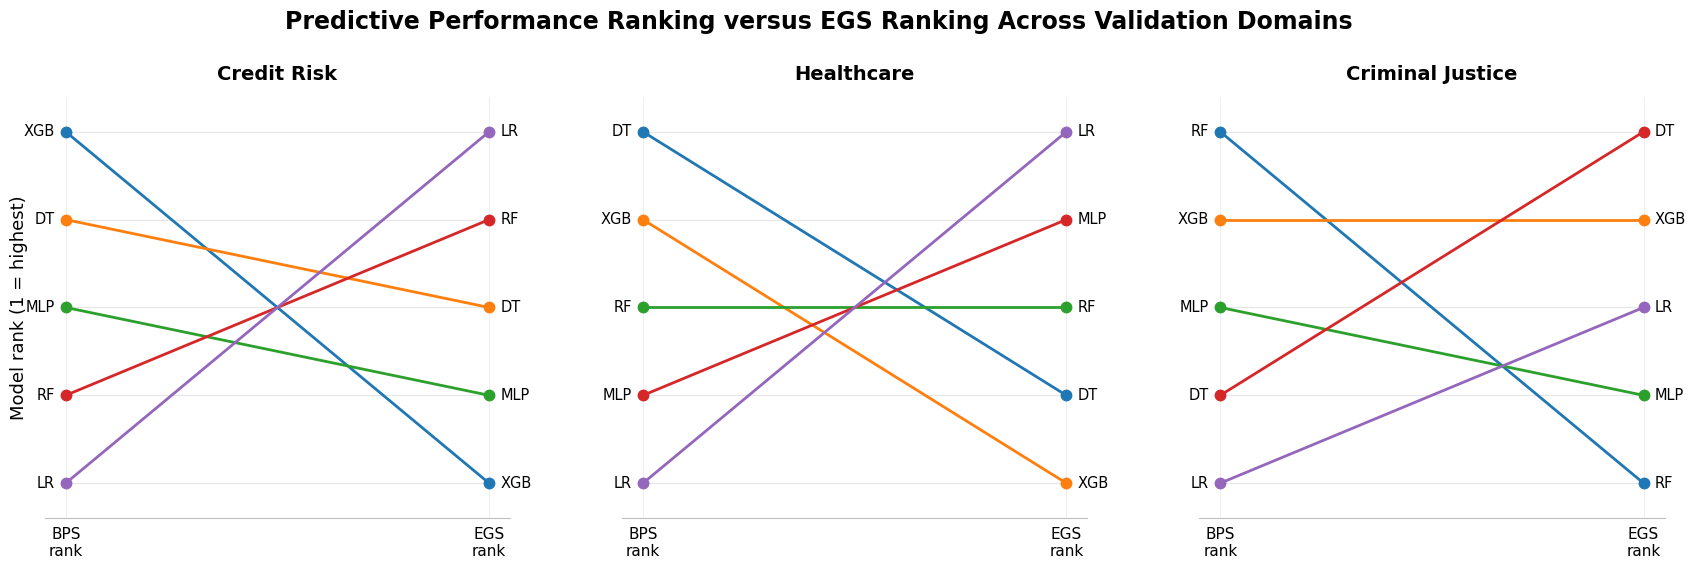

Combined PNG saved to: /content/publication_figures/predictive_vs_egs_rankings_combined.png
Combined SVG saved to: /content/publication_figures/predictive_vs_egs_rankings_combined.svg


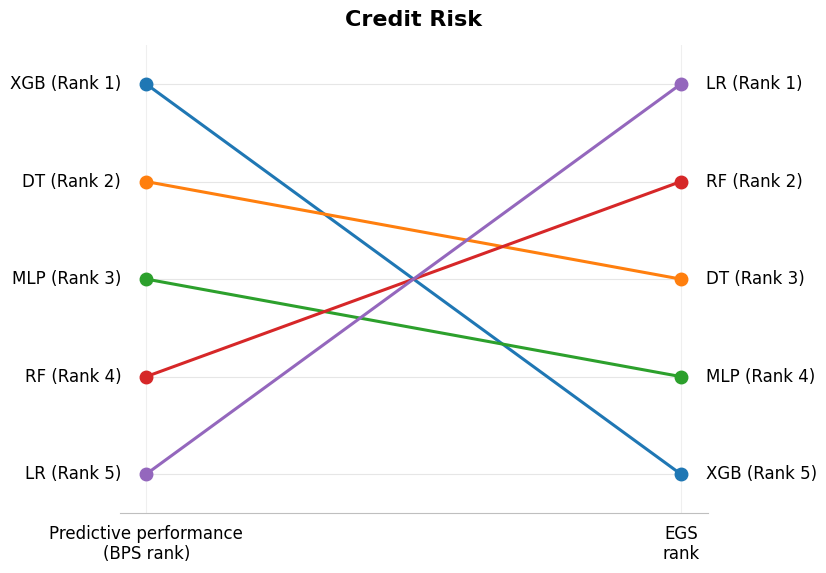

Credit Risk PNG saved to: /content/publication_figures/credit_risk_predictive_vs_egs_rankings.png
Credit Risk SVG saved to: /content/publication_figures/credit_risk_predictive_vs_egs_rankings.svg
Credit Risk PDF saved to: /content/publication_figures/credit_risk_predictive_vs_egs_rankings.pdf


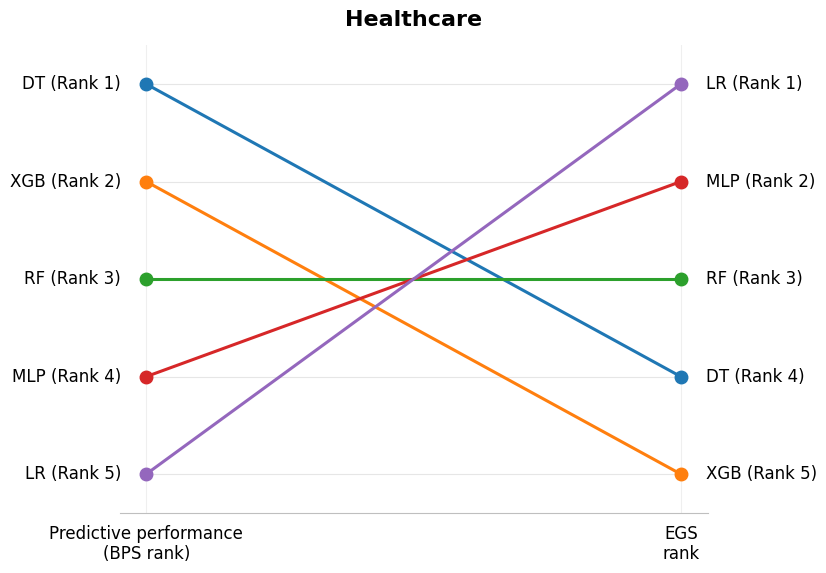

Healthcare PNG saved to: /content/publication_figures/healthcare_predictive_vs_egs_rankings.png
Healthcare SVG saved to: /content/publication_figures/healthcare_predictive_vs_egs_rankings.svg
Healthcare PDF saved to: /content/publication_figures/healthcare_predictive_vs_egs_rankings.pdf


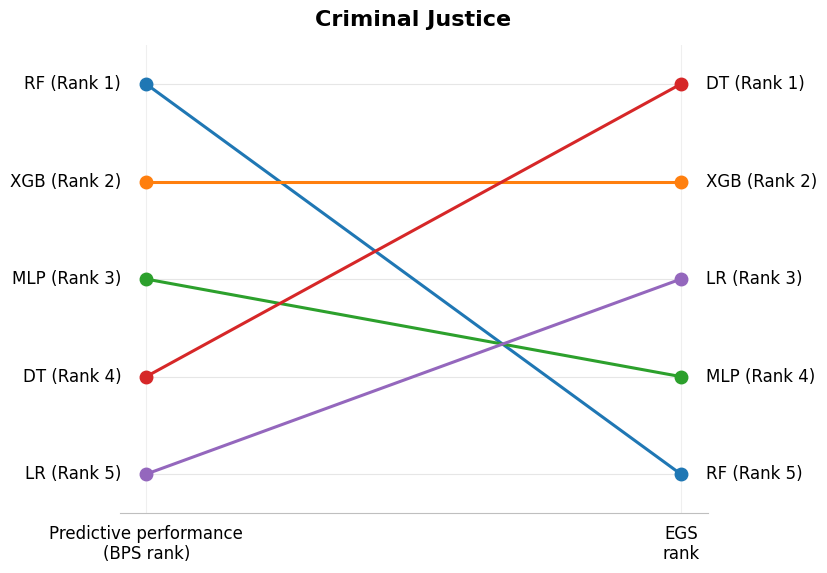

Criminal Justice PNG saved to: /content/publication_figures/criminal_justice_predictive_vs_egs_rankings.png
Criminal Justice SVG saved to: /content/publication_figures/criminal_justice_predictive_vs_egs_rankings.svg
Criminal Justice PDF saved to: /content/publication_figures/criminal_justice_predictive_vs_egs_rankings.pdf

Publication figures generated successfully.
Output folder: /content/publication_figures
Resolution: 600 DPI for PNG outputs
Separate figures include model abbreviations and explicit rank numbers at both endpoints.


In [1]:
# ============================================================
# Predictive Performance Ranking versus EGS Ranking
# Google Colab-ready
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Output configuration
# ------------------------------------------------------------

OUTPUT_DIR = Path("/content/publication_figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DPI = 600

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.titlesize": 14,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.20,
})

# ------------------------------------------------------------
# 2. Model abbreviations
# ------------------------------------------------------------

MODEL_SHORT = {
    "Logistic Regression": "LR",
    "Decision Tree": "DT",
    "Random Forest": "RF",
    "XGBoost": "XGB",
    "MLP": "MLP",
}

# ------------------------------------------------------------
# 3. Final BPS rankings
# ------------------------------------------------------------

baseline = pd.DataFrame([
    # Credit Risk
    ["Credit Risk", "XGBoost", 1],
    ["Credit Risk", "Decision Tree", 2],
    ["Credit Risk", "MLP", 3],
    ["Credit Risk", "Random Forest", 4],
    ["Credit Risk", "Logistic Regression", 5],

    # Healthcare
    ["Healthcare", "Decision Tree", 1],
    ["Healthcare", "XGBoost", 2],
    ["Healthcare", "Random Forest", 3],
    ["Healthcare", "MLP", 4],
    ["Healthcare", "Logistic Regression", 5],

    # Criminal Justice
    ["Criminal Justice", "Random Forest", 1],
    ["Criminal Justice", "XGBoost", 2],
    ["Criminal Justice", "MLP", 3],
    ["Criminal Justice", "Decision Tree", 4],
    ["Criminal Justice", "Logistic Regression", 5],
], columns=["Domain", "Model name", "BPS rank"])


# ------------------------------------------------------------
# 4. Final EGS rankings
# ------------------------------------------------------------

egs = pd.DataFrame([
    # Credit Risk
    ["Credit Risk", "Logistic Regression", 1],
    ["Credit Risk", "Random Forest", 2],
    ["Credit Risk", "Decision Tree", 3],
    ["Credit Risk", "MLP", 4],
    ["Credit Risk", "XGBoost", 5],

    # Healthcare
    ["Healthcare", "Logistic Regression", 1],
    ["Healthcare", "MLP", 2],
    ["Healthcare", "Random Forest", 3],
    ["Healthcare", "Decision Tree", 4],
    ["Healthcare", "XGBoost", 5],

    # Criminal Justice
    ["Criminal Justice", "Decision Tree", 1],
    ["Criminal Justice", "XGBoost", 2],
    ["Criminal Justice", "Logistic Regression", 3],
    ["Criminal Justice", "MLP", 4],
    ["Criminal Justice", "Random Forest", 5],
], columns=["Domain", "Model name", "EGS rank"])


# ------------------------------------------------------------
# 5. Plot
# ------------------------------------------------------------
# ------------------------------------------------------------
# 5. Plotting helpers
# ------------------------------------------------------------

DOMAIN_ORDER = ["Credit Risk", "Healthcare", "Criminal Justice"]

def get_domain_rankings(domain):
    """Return merged BPS and EGS ranks for one validation domain."""
    b = baseline[
        baseline["Domain"] == domain
    ][["Model name", "BPS rank"]]

    e = egs[
        egs["Domain"] == domain
    ][["Model name", "EGS rank"]]

    return (
        b.merge(e, on="Model name", how="inner")
         .sort_values("BPS rank")
    )


def draw_rank_panel(ax, domain, separate=False):
    """Draw one publication-ready slopegraph comparing BPS and EGS ranks."""
    merged = get_domain_rankings(domain)

    # Light horizontal guides for ranks 1–5
    for rank in [1, 2, 3, 4, 5]:
        ax.hlines(
            y=rank,
            xmin=0,
            xmax=1,
            color="0.90",
            linewidth=0.8,
            zorder=0,
        )

    for _, row in merged.iterrows():
        bps_rank = int(row["BPS rank"])
        egs_rank = int(row["EGS rank"])
        model = MODEL_SHORT[row["Model name"]]

        ax.plot(
            [0, 1],
            [bps_rank, egs_rank],
            marker="o",
            linewidth=2.2 if separate else 2.0,
            markersize=9 if separate else 7.5,
            zorder=2,
        )

        if separate:
            # Direct endpoint labels; rank information is embedded in the label.
            ax.annotate(
                f"{model} (Rank {bps_rank})",
                xy=(0, bps_rank),
                xytext=(-18, 0),
                textcoords="offset points",
                ha="right",
                va="center",
                fontsize=12,
                annotation_clip=False,
            )
            ax.annotate(
                f"{model} (Rank {egs_rank})",
                xy=(1, egs_rank),
                xytext=(18, 0),
                textcoords="offset points",
                ha="left",
                va="center",
                fontsize=12,
                annotation_clip=False,
            )
        else:
            ax.annotate(
                model,
                xy=(0, bps_rank),
                xytext=(-8, 0),
                textcoords="offset points",
                ha="right",
                va="center",
                fontsize=10.5,
                annotation_clip=False,
            )
            ax.annotate(
                model,
                xy=(1, egs_rank),
                xytext=(8, 0),
                textcoords="offset points",
                ha="left",
                va="center",
                fontsize=10.5,
                annotation_clip=False,
            )

    # Rank 1 at the top
    ax.set_ylim(5.4, 0.6)
    ax.set_xlim(-0.05, 1.05)

    # Remove the conventional y-axis entirely: rank is already in endpoint labels.
    ax.set_yticks([])
    ax.set_ylabel("")
    ax.spines["left"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

    # Use clean column labels rather than a conventional x-axis.
    ax.set_xticks([0, 1])
    if separate:
        ax.set_xticklabels(
            ["Predictive performance\n(BPS rank)", "EGS\nrank"],
            fontsize=12,
        )
        ax.tick_params(axis="x", length=0, pad=8)
        ax.set_title(domain, fontsize=16, fontweight="bold", pad=14)
    else:
        ax.set_xticklabels(["BPS\nrank", "EGS\nrank"], fontsize=11)
        ax.tick_params(axis="x", length=0, pad=6)
        ax.set_title(domain, fontsize=14, fontweight="bold", pad=12)

    # Keep only a very subtle bottom spine.
    ax.spines["bottom"].set_color("0.75")
    ax.spines["bottom"].set_linewidth(0.8)


# ------------------------------------------------------------
# 6. Combined publication-quality figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6.2),
    sharey=True
)

for ax, domain in zip(axes, DOMAIN_ORDER):
    draw_rank_panel(ax, domain, separate=False)

axes[0].set_ylabel(
    "Model rank (1 = highest)",
    fontsize=13,
    labelpad=12
)

fig.suptitle(
    "Predictive Performance Ranking versus EGS Ranking Across Validation Domains",
    fontsize=17,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    left=0.07,
    right=0.97,
    bottom=0.16,
    top=0.84,
    wspace=0.24
)

combined_png = OUTPUT_DIR / "predictive_vs_egs_rankings_combined.png"
combined_svg = OUTPUT_DIR / "predictive_vs_egs_rankings_combined.svg"

fig.savefig(
    combined_png,
    dpi=DPI,
    bbox_inches="tight"
)

fig.savefig(
    combined_svg,
    bbox_inches="tight"
)

plt.show()

print(f"Combined PNG saved to: {combined_png}")
print(f"Combined SVG saved to: {combined_svg}")


# ------------------------------------------------------------
# 7. Separate publication-quality figures by validation domain
# ------------------------------------------------------------

domain_file_names = {
    "Credit Risk": "credit_risk_predictive_vs_egs_rankings",
    "Healthcare": "healthcare_predictive_vs_egs_rankings",
    "Criminal Justice": "criminal_justice_predictive_vs_egs_rankings",
}

for domain in DOMAIN_ORDER:
    fig, ax = plt.subplots(figsize=(10.5, 6.5))

    draw_rank_panel(ax, domain, separate=True)

    fig.subplots_adjust(left=0.22, right=0.78, top=0.88, bottom=0.16)

    base_name = domain_file_names[domain]
    png_path = OUTPUT_DIR / f"{base_name}.png"
    svg_path = OUTPUT_DIR / f"{base_name}.svg"
    pdf_path = OUTPUT_DIR / f"{base_name}.pdf"

    fig.savefig(
        png_path,
        dpi=DPI,
        bbox_inches="tight"
    )

    fig.savefig(
        svg_path,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    plt.show()

    print(f"{domain} PNG saved to: {png_path}")
    print(f"{domain} SVG saved to: {svg_path}")
    print(f"{domain} PDF saved to: {pdf_path}")


# ------------------------------------------------------------
# 8. Output summary
# ------------------------------------------------------------

print("\nPublication figures generated successfully.")
print(f"Output folder: {OUTPUT_DIR}")
print("Resolution: 600 DPI for PNG outputs")
print("Separate figures include model abbreviations and explicit rank numbers at both endpoints.")


In [ ]:
%pip install lime dice-ml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 42.2 MB/s eta 0:00:00
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=491b76e95b4dbe6ded98152a3485b0d91a7b1db770bd9c4161bc0ee0e31a54f4
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [ ]:
import sys
import sklearn
import xgboost
import shap
import lime
import dice_ml
import importlib.metadata as md

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)
print("LIME:", md.version("lime"))
print("DiCE:", md.version("dice-ml"))

Python: 3.13.15
scikit-learn: 1.6.1
XGBoost: 3.4.1
SHAP: 0.52.0
LIME: 0.2.0.1
DiCE: 0.12
